1. ISTAT Data

Import the necessary libraries and modules

In [ ]:
import pandas as pd
import requests
from pathlib import Path

url = "https://esploradati.istat.it/SDMXWS/rest/data/41_983"
header = {"Accept": "application/vnd.sdmx.data+csv;version=1.0.0"}

cartella_raw = Path("../data/raw")
file_istat = cartella_raw / "istat_incidenti.csv"

Download the file from the URL and save it to the specified path

In [ ]:
r = requests.get(url, headers=header)
print(r.status_code)

if r.status_code == 200:
    cartella_raw.mkdir(parents=True, exist_ok=True)
    with open(file_istat, "wb") as f:
        f.write(r.content)
    print(f"File downloaded and saved in {file_istat}")

200
File downloaded and saved in ..\data\raw\istat_incidenti.csv


Create a DataFrame from the downloaded CSV file and display its shape 

REF_AREA is set to string type to avoid any issues with leading zeros in the area codes.

In [ ]:
df_istat = pd.read_csv(file_istat, dtype={"REF_AREA": str})
df_istat.shape

(573552, 16)

Print all the columns name of the dataframe and the first 5 rows of the dataframe

In [ ]:
print(df_istat.columns.tolist())
df_istat.head()

['DATAFLOW', 'FREQ', 'REF_AREA', 'DATA_TYPE', 'RESULT', 'TIME_PERIOD', 'OBS_VALUE', 'OBS_STATUS', 'NOTE_DS', 'NOTE_REF_AREA', 'NOTE_DATA_TYPE', 'NOTE_RESULT', 'NOTE_TIME_PERIOD', 'BASE_PER', 'UNIT_MEAS', 'UNIT_MULT']


,DATAFLOW,FREQ,REF_AREA,DATA_TYPE,RESULT,TIME_PERIOD,OBS_VALUE,OBS_STATUS,NOTE_DS,NOTE_REF_AREA,NOTE_DATA_TYPE,NOTE_RESULT,NOTE_TIME_PERIOD,BASE_PER,UNIT_MEAS,UNIT_MULT
0,IT1:41_983(1.0),A,001001,KILLINJ,F,2001,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,IT1:41_983(1.0),A,001001,KILLINJ,F,2002,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,IT1:41_983(1.0),A,001001,KILLINJ,F,2003,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,IT1:41_983(1.0),A,001001,KILLINJ,F,2004,13,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,IT1:41_983(1.0),A,001001,KILLINJ,F,2005,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Print the value counts of the columns "FREQ", "DATA_TYPE", and "RESULT", to veiw the distribution of the values in these columns

In [ ]:
for column in ["FREQ", "DATA_TYPE", "RESULT"]:
    print(column)
    print(df_istat[column].value_counts(), "\n")

FREQ
FREQ
A    573552
Name: count, dtype: int64 

DATA_TYPE
DATA_TYPE
KILLINJ    382368
ROADACC    191184
Name: count, dtype: int64 

RESULT
RESULT
F    191184
M    191184
9    191184
Name: count, dtype: int64 



Some analysis: 

Column FREQ represents the frequency of the data, which is annual (A). 

Column DATA_TYPE represents the type of data which is observed; killinj stands for killed/Injured, roadacc stands for road accidents.

Column RESULT represents the result of the data, which is a value. F means injured, M means killed, 9 it's only a number that represents accident

Check how many Municipalities are in the dataset

Check lenght code of the municipalities, to see if there are any anomalies in the data

In [ ]:
print("Distinct Municipalities:", df_istat["REF_AREA"].nunique())
print(df_istat["REF_AREA"].str.len().value_counts())

Distinct Municipalities: 8578
REF_AREA
6    573552
Name: count, dtype: int64


Point of attention: today there are more or less 7.900 municipalities in Italy, but in the dataset there are 8.578 municipalities. 

This is because the dataset contains also some municipalities that have been merged or abolished over time.

We have to be careful when we're gonna merge this dataset with the SITUAS dataset.

Let's see how many years are in the dataset and how many data points are available for each year.

In [ ]:
print(df_istat["TIME_PERIOD"].value_counts().sort_index())

TIME_PERIOD
2001    24303
2002    24306
2003    24306
2004    24300
2005    24303
2006    24303
2007    24303
2008    24303
2009    24300
2010    24282
2011    24276
2012    24276
2013    24276
2014    24177
2015    24141
2016    24000
2017    23934
2018    23862
2019    23745
2020    23712
2021    23712
2022    23712
2023    23703
2024    19017
Name: count, dtype: int64


Print some data statistics for the column "OBS_VALUE" and check for missing values in the dataframe

In [ ]:
print(df_istat["OBS_VALUE"].describe())
print("Missing Values for column:")
print(df_istat.isna().sum())

count    573552.000000
mean         20.207603
std         245.813966
min           0.000000
25%           0.000000
50%           1.000000
75%           8.000000
max       30254.000000
Name: OBS_VALUE, dtype: float64
Missing Values for column:
DATAFLOW                 0
FREQ                     0
REF_AREA                 0
DATA_TYPE                0
RESULT                   0
TIME_PERIOD              0
OBS_VALUE                0
OBS_STATUS          573552
NOTE_DS             573552
NOTE_REF_AREA       573552
NOTE_DATA_TYPE      573552
NOTE_RESULT         573552
NOTE_TIME_PERIOD    573552
BASE_PER            573552
UNIT_MEAS           573552
UNIT_MULT           573552
dtype: int64


As we can see, the last 9 columns are totally empty, so we can drop them from the dataframe.

We can also drop the first 2 columns (DATAFLOW and FREQ) beacuse they are not useful for our analysis.

We can notice that the max value of column OBS_VALUE is very high, so we can check if there are any outliers in the data.

There are three rows from the column RESULT for every year and every munipalities.

We need a row for every year and every munipalities and a column for every RESULT, so we have to pivot the dataframe.

In [9]:
df = df_istat.copy()
df["RESULT"] = df["RESULT"].astype(str)

df_municipalities = (
    df.pivot(index=["REF_AREA", "TIME_PERIOD"], columns="RESULT", values="OBS_VALUE")
      .rename(columns={"9": "accidents", "M": "deaths", "F": "injured"})
      .reset_index()
)
df_municipalities.columns.name = None
df_municipalities.head()

,REF_AREA,TIME_PERIOD,accidents,injured,deaths
0,001001,2001,5,10,0
1,001001,2002,5,10,0
2,001001,2003,4,7,0
3,001001,2004,9,13,0
4,001001,2005,2,2,0


In [10]:
df_municipalities[["accidents", "deaths", "injured"]].describe()

,accidents,deaths,injured
count,191184.000000,191184.000000,191184.000000
mean,24.997599,0.533225,35.091985
std,257.519973,2.783505,338.109881
min,0.000000,0.000000,0.000000
25%,1.000000,0.000000,1.000000
50%,3.000000,0.000000,5.000000
75%,12.000000,0.000000,18.000000
max,23135.000000,363.000000,30254.000000


We're gonna plot a graphic to see the trend of accidents and injured in Italy over the years, and to see if the number of accidents in 2024 is higher than 2023.

We need to do this check because the number of municipalities in 2024 is significantly lower than 2023; we have to be sure that the missing municipalities are a choice of Istat (municipalities with 0 accidents, so eliminated) and not missing datas.

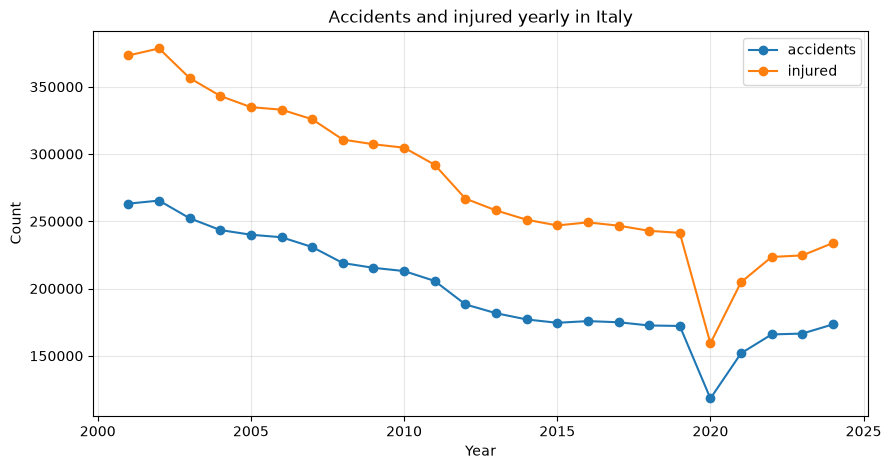

In [11]:
import matplotlib.pyplot as plt

total_incidents_yearly = df_municipalities.groupby("TIME_PERIOD")[["accidents", "injured"]].sum()

total_incidents_yearly.plot(marker="o", figsize=(10, 5))
plt.title("Accidents and injured yearly in Italy")
plt.xlabel("Year")
plt.ylabel("Count")
plt.grid(alpha=0.3)
plt.show()

As a result, we can see that the number of accidents and injured in 2024 is lower than 2023, so we can conclude that the missing municipalities are a choice of Istat and not missing datas.

Let's save the processed dataframe to a CSV file in the "processed" folder.

In [ ]:
cartella_processed = Path("../data/processed")
cartella_processed.mkdir(parents=True, exist_ok=True)

df_municipalities.to_csv(cartella_processed / "municipalities_accidents.csv", index=False)
print("Saved:", df_municipalities.shape)

Saved: (191184, 5)
